In [1]:
import pandas as pd

df = pd.read_csv("dataset.csv")

df.head()

,Name,Timestamp,X,Y
0,qdugzqd,"Jan 26, 2026, 12:00:03 AM",54.019410,69.212326
1,qdugzqd,"Jan 26, 2026, 12:00:03 AM",176.670391,66.628831
2,qdugzqd,"Jan 26, 2026, 12:00:03 AM",185.917840,105.632155
3,qdugzqd,"Jan 26, 2026, 12:00:03 AM",127.891247,52.613789
4,qdugzqd,"Jan 26, 2026, 12:00:03 AM",89.019781,36.288286


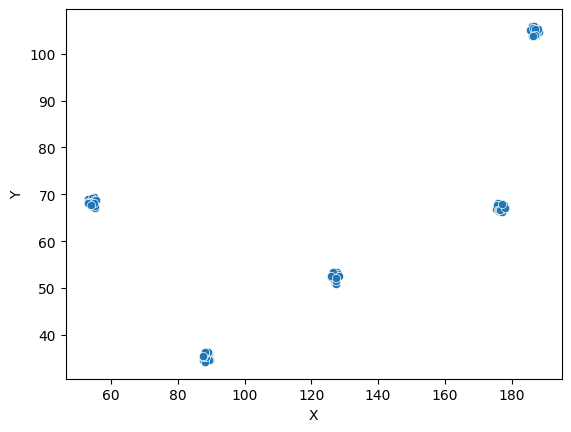

In [2]:
#subtaskuri
subtask1 = df.Timestamp.nunique()

import matplotlib.pyplot as plt
import seaborn as sns

subtask2 = 5 # se vad 5 clusteruri (am micsorat numaru de sample uri sa se vada bine)

sns.scatterplot(x=df.X[100:200], y=df.Y[100:200])
plt.show()

In [3]:
df_1 = pd.DataFrame({
    "id": "GLOBAL",
    "subtaskID": ["task1", "task2"],
    "answer": [subtask1, subtask2]
})

df_1

,id,subtaskID,answer
0,GLOBAL,task1,50
1,GLOBAL,task2,5


[[ 88.7628524   35.30249776]
 [186.82262315 104.63050812]
 [ 54.62844385  68.35512374]
 [127.11129975  52.15543685]
 [176.66201506  67.23041177]]


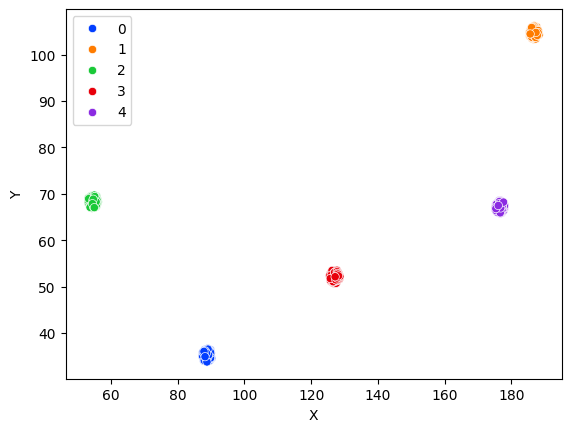

In [4]:
from sklearn.cluster import KMeans # asta e principiul gen pt fiecare timestamp
time = df.Timestamp[90]
sparks = df[df.Timestamp == time][['X', 'Y']]

model = KMeans(n_clusters=5, random_state=42, n_init=20)
labels = model.fit_predict(sparks)

print(model.cluster_centers_)

sns.scatterplot(x=sparks.X, y=sparks.Y, hue=labels, palette='bright')
plt.show()

In [8]:
df['seconds'] = pd.to_datetime(df['Timestamp'], format="%b %d, %Y, %I:%M:%S %p")
df['seconds'] = (df['seconds'] - df['seconds'].min()).dt.total_seconds()

df.head()

,Name,Timestamp,X,Y,seconds
0,qdugzqd,"Jan 26, 2026, 12:00:03 AM",54.019410,69.212326,0.0
1,qdugzqd,"Jan 26, 2026, 12:00:03 AM",176.670391,66.628831,0.0
2,qdugzqd,"Jan 26, 2026, 12:00:03 AM",185.917840,105.632155,0.0
3,qdugzqd,"Jan 26, 2026, 12:00:03 AM",127.891247,52.613789,0.0
4,qdugzqd,"Jan 26, 2026, 12:00:03 AM",89.019781,36.288286,0.0


In [9]:
from sklearn.metrics import silhouette_score

all_centers = []

for time in sorted(df.Timestamp.unique()):
    sparks = df[df.Timestamp == time][['X', 'Y']]
    seconds = df[df.Timestamp == time]['seconds'].iloc[0]

    model = KMeans(n_clusters=5, random_state=42, n_init=10)
    labels = model.fit_predict(sparks)
    centers = model.cluster_centers_

    score = silhouette_score(sparks, labels)

    for i in range(5):
        all_centers.append({
            'time': time,
            'seconds': seconds,
            'cluster': i,
            'X': centers[i][0],
            'Y': centers[i][1],
            'good': score > 0.9
        })

In [11]:
centers_df = pd.DataFrame(all_centers)
centers_df.tail()

,time,seconds,cluster,X,Y,good
245,"Jan 26, 2026, 12:05:47 AM",344.0,0,143.121654,109.887079,False
246,"Jan 26, 2026, 12:05:47 AM",344.0,1,231.040724,143.000046,False
247,"Jan 26, 2026, 12:05:47 AM",344.0,2,106.998639,146.483472,False
248,"Jan 26, 2026, 12:05:47 AM",344.0,3,181.163063,128.875904,False
249,"Jan 26, 2026, 12:05:47 AM",344.0,4,240.258278,181.618021,False


In [13]:
from sklearn.linear_model import LinearRegression

centers_df['predX'] = 0.0
centers_df['predY'] = 0.0

for cl in range(5):
    train = centers_df[(centers_df['cluster'] == cl) & (centers_df['good'])]

    lx = LinearRegression().fit(train[['seconds']], train['X'])
    ly = LinearRegression().fit(train[['seconds']], train['Y'])

    mask = centers_df['cluster'] == cl
    centers_df.loc[mask, 'predX'] = lx.predict(centers_df.loc[mask, ['seconds']])
    centers_df.loc[mask, 'predY'] = ly.predict(centers_df.loc[mask, ['seconds']])

centers_df.head()

,time,seconds,cluster,X,Y,good,predX,predY
0,"Jan 26, 2026, 12:00:03 AM",0.0,0,88.762852,35.302498,True,88.789307,35.146250
1,"Jan 26, 2026, 12:00:03 AM",0.0,1,186.822623,104.630508,True,186.804900,104.677764
2,"Jan 26, 2026, 12:00:03 AM",0.0,2,54.628444,68.355124,True,54.576311,68.429291
3,"Jan 26, 2026, 12:00:03 AM",0.0,3,127.111300,52.155437,True,127.011300,52.191258
4,"Jan 26, 2026, 12:00:03 AM",0.0,4,176.662015,67.230412,True,176.589170,67.087570


In [14]:
ids = []
answers = []

for _, row in centers_df.iterrows():
    ids.append(f"{row['time']}|{int(row['cluster'])}")
    answers.append(f"{row['predX']}|{row['predY']}")

answers[:5]

['88.78930680404444|35.146250365963674',
 '186.80490035433954|104.67776440757042',
 '54.57631122049765|68.42929132468609',
 '127.01129965997248|52.191257754448486',
 '176.5891702540442|67.08756957228368']

In [15]:
df_2 = pd.DataFrame({
    "id": ids,
    "subtaskID": "task3",
    "answer": answers
})

df_2.head()

,id,subtaskID,answer
0,"Jan 26, 2026, 12:00:03 AM|0",task3,88.78930680404444|35.146250365963674
1,"Jan 26, 2026, 12:00:03 AM|1",task3,186.80490035433954|104.67776440757042
2,"Jan 26, 2026, 12:00:03 AM|2",task3,54.57631122049765|68.42929132468609
3,"Jan 26, 2026, 12:00:03 AM|3",task3,127.01129965997248|52.191257754448486
4,"Jan 26, 2026, 12:00:03 AM|4",task3,176.5891702540442|67.08756957228368


In [31]:
future_time = pd.to_datetime("Jan 26, 2026, 12:08:20 AM", format="%b %d, %Y, %I:%M:%S %p")
t0 = pd.to_datetime(df['Timestamp'], format="%b %d, %Y, %I:%M:%S %p").min()
future_sec = (future_time - t0).total_seconds()

task4_ans = []
task4_ids = []

for cl in range(5):
    train = centers_df[(centers_df['cluster'] == cl) & (centers_df['good'])]

    lx = LinearRegression().fit(train[['seconds']], train['X'])
    ly = LinearRegression().fit(train[['seconds']], train['Y'])

    x = lx.predict(pd.DataFrame({'seconds': [future_sec]}))[0]
    y = ly.predict(pd.DataFrame({'seconds': [future_sec]}))[0]

    task4_ans.append(f"{x}|{y}")
    task4_ids.append(f"Jan 26, 2026, 12:08:20 AM|{cl}")

task4_ans[0]

'166.7700938037405|146.1192202799004'

In [32]:
df_3 = pd.DataFrame({
    "id": task4_ids,
    "subtaskID": "task4",
    "answer": task4_ans
})

df_3.head()

,id,subtaskID,answer
0,"Jan 26, 2026, 12:08:20 AM|0",task4,166.7700938037405|146.1192202799004
1,"Jan 26, 2026, 12:08:20 AM|1",task4,264.97386241479535|215.727263028515
2,"Jan 26, 2026, 12:08:20 AM|2",task4,132.57028174755465|179.0684031990623
3,"Jan 26, 2026, 12:08:20 AM|3",task4,205.16673503933998|163.07272115039706
4,"Jan 26, 2026, 12:08:20 AM|4",task4,254.52371717816868|178.0915016064089


In [33]:
submission = pd.concat([df_1, df_2, df_3])
submission.to_csv("submission.csv", index=False)

In [34]:
submission

,id,subtaskID,answer
0,GLOBAL,task1,50
1,GLOBAL,task2,5
0,"Jan 26, 2026, 12:00:03 AM|0",task3,88.78930680404444|35.146250365963674
1,"Jan 26, 2026, 12:00:03 AM|1",task3,186.80490035433954|104.67776440757042
2,"Jan 26, 2026, 12:00:03 AM|2",task3,54.57631122049765|68.42929132468609
...,...,...,...
0,"Jan 26, 2026, 12:08:20 AM|0",task4,166.7700938037405|146.1192202799004
1,"Jan 26, 2026, 12:08:20 AM|1",task4,264.97386241479535|215.727263028515
2,"Jan 26, 2026, 12:08:20 AM|2",task4,132.57028174755465|179.0684031990623
3,"Jan 26, 2026, 12:08:20 AM|3",task4,205.16673503933998|163.07272115039706
